<a href="https://colab.research.google.com/github/saharmansourirad/single-cell-rna-seq-analysis/blob/main/01_scRNA_seq_QC_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
%pip install -q "anndata==0.11.4" "scanpy==1.11.5" "pandas==2.2.3"
%pip install -q scanpy
%pip install -q "zarr<3"
%pip install -q igraph leidenalg

In [7]:
import pandas as pd
import scanpy as sc
from importlib.metadata import version

print("Pandas:", version("pandas"))
print("AnnData:", version("anndata"))
print("Scanpy:", version("scanpy"))

Pandas: 2.2.3
AnnData: 0.11.4
Scanpy: 1.11.5


In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 2 # print informational messages and progress

adata = sc.datasets.pbmc3k()

print(adata)
print("Cells:", adata.n_obs) # number of cells
print("Genes:", adata.n_vars) # number of genes

try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
Cells: 2700
Genes: 32738


### Number of Genes Detected per Cell (`n_genes_by_counts`)

`n_genes_by_counts` is calculated from the count matrix. It is not the count of a single entry; instead, it counts how many genes have a nonzero value in each cell.

### Example

Suppose the count matrix looks like this:

| Cell | Gene A | Gene B | Gene C | Gene D |
|---|---:|---:|---:|---:|
| Cell 1 | 5 | 2 | 0 | 3 |
| Cell 2 | 0 | 4 | 0 | 0 |
| Cell 3 | 1 | 0 | 7 | 2 |

Scanpy counts the genes with values greater than zero in each row:

- **Cell 1:** `n_genes_by_counts = 3` (Genes A, B and D).
- **Cell 2:** `n_genes_by_counts = 1` (Gene B).
- **Cell 3:** `n_genes_by_counts = 3` (Genes A, C and D).

### Key Takeaway

A gene is considered detected when its observed count is greater than zero. Therefore, `n_genes_by_counts` measures the number of detected genes in each cell, not the total number of RNA counts.

In [8]:
# Identify mitochondrial genes in human data
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate QC metrics for each cell
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    inplace=True
)
# PBMC 3k dataset with Scanpy, the count matrix contains UMI-based gene counts.
# Inspect the first few cells
adata.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
index,,,
AAACATACAACCAC-1,781,2421.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,1.743085
AAACCGTGTATGCG-1,522,981.0,1.223242


In [6]:
# which genes in your dataset are mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
print(adata.var["mt"].head())
print(adata.var_names[adata.var["mt"]][:5])


index
MIR1302-10      False
FAM138A         False
OR4F5           False
RP11-34P13.7    False
RP11-34P13.8    False
Name: mt, dtype: bool
Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8'], dtype='object', name='index')


### Identifying Mitochondrial Genes

- `adata.var_names`: Retrieves the names of all genes in the dataset.
- `.str.startswith("MT-")`: Checks whether each gene name starts with `"MT-"` and returns `True` or `False`.
- `adata.var["mt"] =`: Stores these Boolean results in a new column called `mt` in the gene metadata table.

### AnnData Structure

- **`adata.obs`** stores cell-level information, such as QC metrics and cluster labels.
- **`adata.var`** stores gene-level information, such as gene names and whether a gene is mitochondrial.

### Key Takeaway

The `mt` column identifies mitochondrial genes for downstream QC calculations. It does not remove these genes from the dataset.

**Note:** The `"MT-"` prefix is commonly used for human mitochondrial genes. Other organisms may use different naming conventions.

### Understanding QC Metrics

- **`n_genes_by_counts`:** Number of genes detected in each cell.
- **`total_counts`:** Total observed RNA counts across all genes in each cell.
- **`pct_counts_mt`:** Percentage of the cell's total counts that come from mitochondrial genes.

These metrics help assess cell quality. The key difference is that `n_genes_by_counts` counts detected genes, while `total_counts` measures the total observed counts.

### Example

Suppose a cell has these observed counts:

| Gene | Observed counts |
|---|---:|
| Gene A | 5 |
| Gene B | 3 |
| Gene C | 0 |
| Gene D | 2 |
| Gene E | 0 |
| **Total** | **10** |

**1. `n_genes_by_counts` = 3**

Three genes have at least one observed count: A, B and D.

**2. `total_counts` = 10**

The total is the sum of all observed counts: 5 + 3 + 0 + 2 + 0 = 10.

**3. `pct_counts_mt` = 20% (example)**

If 2 of the 10 counts come from mitochondrial genes, the mitochondrial percentage is 20%.

### Why Do We Need Both Gene Counts and Total Counts?

| Metric | Cell A | Cell B |
|---|---:|---:|
| Detected genes | 1,000 | 1,000 |
| Total counts | 2,000 | 10,000 |
| Average counts per detected gene | 2 | 10 |

Both cells have the same number of detected genes, but Cell B has five times as many observed counts. This can reflect differences in RNA abundance, RNA capture or sequencing depth.

### Interpreting QC Metrics

- **Low `n_genes_by_counts`:** May indicate a low-quality cell, an empty droplet or a cell with little RNA.
- **Low `total_counts`:** May indicate low sequencing depth or low RNA content.
- **High `pct_counts_mt`:** May indicate a damaged or stressed cell, although normal values vary by cell type and tissue.

**Key takeaway:** These metrics help identify potentially low-quality cells, but thresholds should be chosen based on the dataset rather than applied universally.

Y-axis (vertical): the number of detected genes per cell.

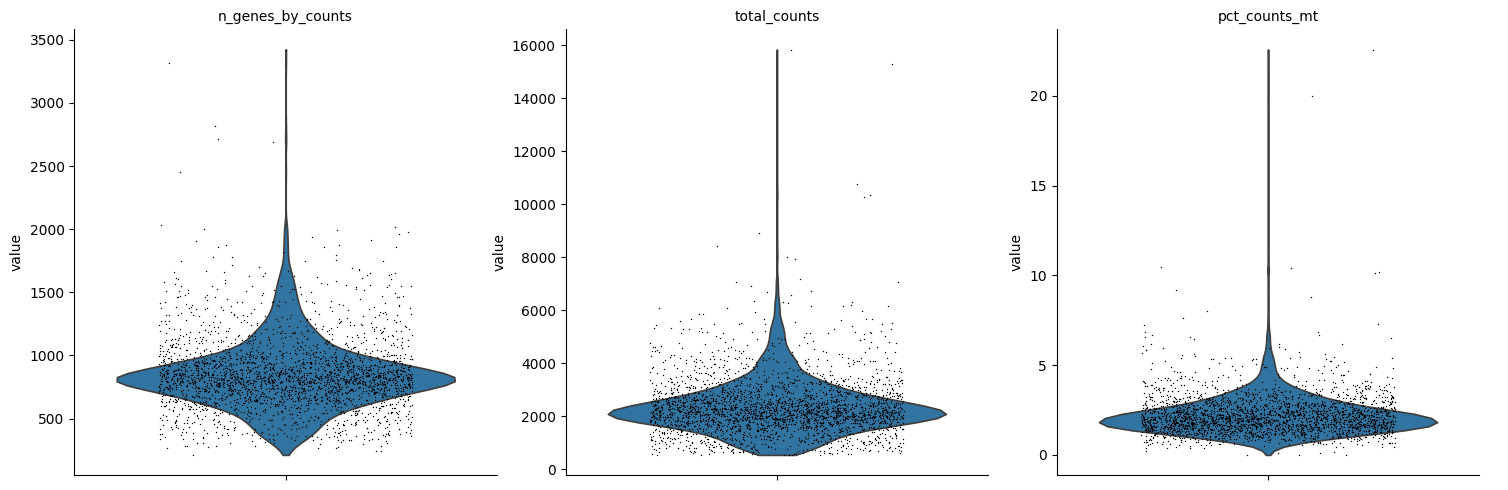

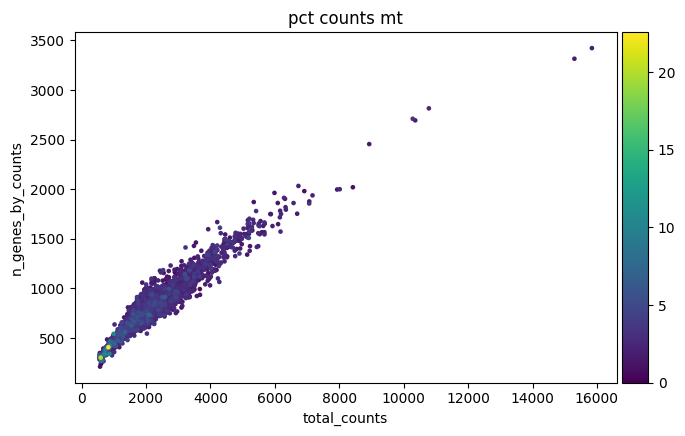

In [9]:
# Visualize cell quality
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.3,
    multi_panel=True
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

**Plots before filtering**

 Cells with very few detected genes may be low quality.

Cells with unusually high counts or gene numbers may be doublets.

 High mitochondrial percentages can indicate stressed or damaged cells, although this depends on the tissue and experiment.

In [15]:
#Filter cells and genes

print("Before filtering:", adata.shape)

# Remove cells with fewer than 200 detected genes
sc.pp.filter_cells(adata, min_genes=200)

# Remove genes detected in fewer than 3 cells
sc.pp.filter_genes(adata, min_cells=3)

# Apply a provisional mitochondrial threshold
# cells whose mitochondrial counts make up 15% or more of their total counts.
adata = adata[adata.obs["pct_counts_mt"] < 15].copy() #cell level filtering, because these types of cells are probably damaged

print("After filtering:", adata.shape)

Before filtering: (2700, 32738)
filtered out 19024 genes that are detected in less than 3 cells
After filtering: (2698, 13714)


In [10]:
# Save raw counts and normalize

# Preserve the count matrix before transforming it
adata.layers["counts"] = adata.X.copy()

# Normalize each cell to a total of 10,000 counts
sc.pp.normalize_total(adata, target_sum=1e4)

# Apply log(1 + x) transformation
sc.pp.log1p(adata)

print(adata)

normalizing counts per cell
    finished (0:00:02)
AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


Why do we do this?
- **Normalization** reduces differences caused by cells having different total numbers of observed counts.
- **Log transformation** compresses the range of values so that very large counts have less influence.
We keep the original counts in adata.layers["counts"] because some later analyses need them.

extracting highly variable genes
    finished (0:00:00)
Highly variable genes: 2000


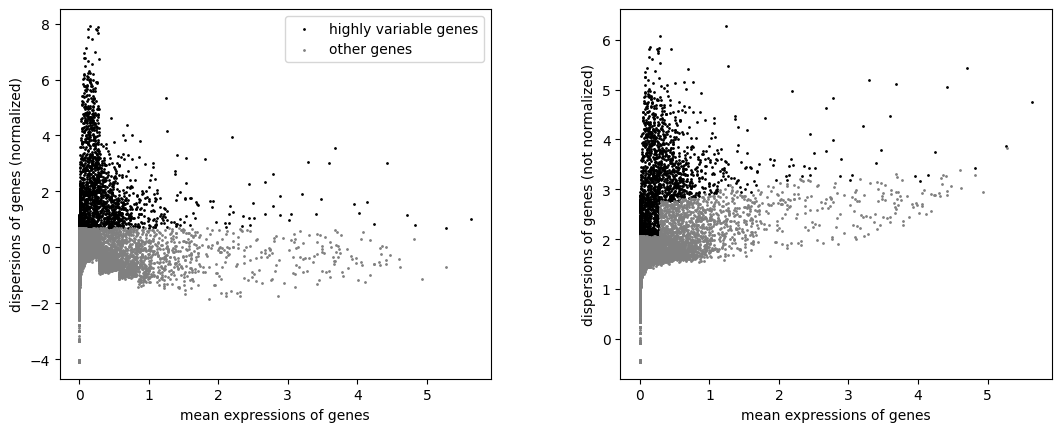

In [11]:
# Select highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print(
    "Highly variable genes:",
    adata.var["highly_variable"].sum()
)

sc.pl.highly_variable_genes(adata)

<div style="font-family: 'Times New Roman'; color: #1F4E79;"> Highly variable genes show substantial variation across cells. They are often useful for discovering cell populations, though variation can also reflect technical effects.
We mark these genes rather than removing the other genes from the dataset.
</div>

In [ ]:
adata.write_h5ad("pbmc3k_preprocessed.h5ad")

print("Saved processed dataset.")

Saved processed dataset.


In [12]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

print(adata_hvg)

AnnData object with n_obs × n_vars = 2700 × 2000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: 'counts'


The .h5ad file stores the **expression matrix**, **metadata** and **preprocessing** **results**.

<div style="font-family: 'Times New Roman', Times, serif;">

### What does scaling mean?

Genes can have very different expression ranges across cells. For example, one gene might have values mostly between 0 and 2, while another has values between 0 and 8.

Scaling standardizes each gene across all cells using a **z-score**:

$$
z = \frac{x-\mu}{\sigma}
$$

- \(x\): the gene's expression value in a particular cell
- \(\mu\): the mean expression of that gene across all cells
- \(\sigma\): the standard deviation of that gene across all cells

After scaling, each gene typically has a mean of 0 and a standard deviation of 1 across cells.

In `sc.pp.scale(adata_hvg, max_value=10)`, the argument `max_value=10` clips scaled values above 10 or below −10. This helps limit the influence of extreme values.

</div>

In [13]:
sc.pp.scale(adata_hvg, max_value=10)

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [14]:
from scipy.sparse import issparse

print("Original adata.X")
print("Type:", type(adata.X))
print("Is sparse:", issparse(adata.X))

print("\nScaled adata_hvg.X")
print("Type:", type(adata_hvg.X))
print("Is sparse:", issparse(adata_hvg.X))

Original adata.X
Type: <class 'scipy.sparse._csr.csr_matrix'>
Is sparse: True

Scaled adata_hvg.X
Type: <class 'numpy.ndarray'>
Is sparse: False


### Sparse vs. Dense Matrices

A **sparse matrix** stores mostly nonzero values efficiently, making it suitable for single-cell RNA-seq data, which contains many zeros. A **dense matrix** stores every value, including zeros.

Before scaling, `adata.X` was sparse. During `sc.pp.scale(adata_hvg, max_value=10)`, Scanpy centered each gene by subtracting its mean, turning many zeros into nonzero values. Therefore, `adata_hvg.X` became a dense NumPy array (`numpy.ndarray`).

**Note:** Sparse matrices save memory, while dense matrices can simplify calculations but require more memory.

In [15]:
print(adata_hvg)
print("Scaled matrix shape:", adata_hvg.X.shape)
print("Matrix type:", type(adata_hvg.X))

AnnData object with n_obs × n_vars = 2700 × 2000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'
    layers: 'counts'
Scaled matrix shape: (2700, 2000)
Matrix type: <class 'numpy.ndarray'>


### What is `arpack` in PCA?

`arpack` is a numerical algorithm used to calculate selected eigenvalues and eigenvectors. In PCA, these help determine the principal components that capture the main patterns of variation in the data.

In `sc.tl.pca(adata_hvg, svd_solver="arpack")`, the argument `svd_solver="arpack"` tells Scanpy to use the ARPACK solver to calculate the principal components.

**Why use it?** ARPACK can efficiently calculate a subset of principal components instead of computing the full decomposition.

**Note:** `arpack` is the solver used for the calculation, while PCA is the dimensionality-reduction method itself.

In [16]:
sc.tl.pca(adata_hvg, svd_solver="arpack")

computing PCA
    with n_comps=50
    finished (0:00:02)


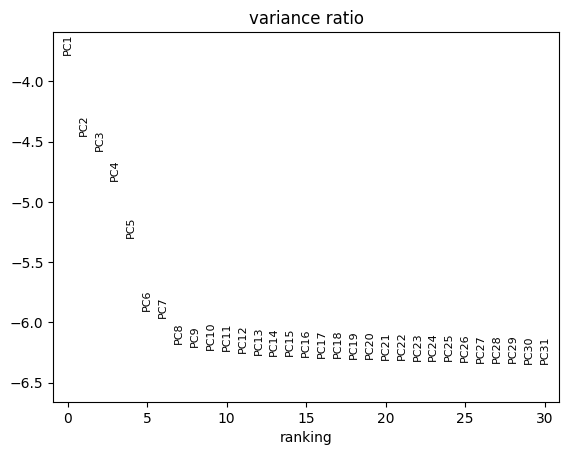

In [17]:
sc.pl.pca_variance_ratio(adata_hvg, log=True)

### Interpreting the PCA Variance Plot

The PCA variance plot shows how much of the total variation in gene expression is explained by each principal component (PC).

- **X-axis:** Principal component number.
- **Y-axis:** Proportion of variance explained by each PC, displayed on a logarithmic scale.
- **PC1:** Captures the greatest possible amount of variation.
- **Later PCs:** Capture progressively smaller amounts of variation.

The **elbow point** is where the explained variance begins to decrease more gradually. It can help us estimate how many PCs to use for downstream analysis.

PCA calculated 50 PCs in this dataset, but we do not necessarily need to use all 50 when constructing the cell-neighbor graph.

In [18]:
#how much variation each PC explains.
print("PCA shape:", adata_hvg.obsm["X_pca"].shape)


PCA shape: (2700, 50)


### Goal of Principal Components (PCs)

PCA reduces thousands of gene measurements into fewer variables while preserving the main patterns of variation between cells.

It combines information from multiple genes into new variables called principal components (PCs). Each PC captures a different pattern of variation.

For example, instead of analyzing 2,000 genes directly, we might use 30 PCs to represent the main patterns of variation across cells.

In [19]:
#Build the neighbor graph
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=15,
    n_pcs=50
)

print("Neighbor graph created.")
print("Graph components:", list(adata_hvg.obsp.keys()))

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:30)
Neighbor graph created.
Graph components: ['distances', 'connectivities']


### Number of PCs Used for the Neighbor Graph

PCA calculated 50 principal components (PCs), but downstream analysis can use fewer PCs.

The `n_pcs` parameter determines how many of the calculated PCs are used to compare cells when building the neighbor graph.

We use `n_pcs=50` to include all 50 calculated PCs for now. The optimal number should be evaluated using the PCA variance plot and the analysis goals.

### Build the Neighbor Graph

After calculating PCA, we build a **neighbor graph** to identify cells with similar gene expression patterns. This graph is used in downstream steps such as Leiden clustering and UMAP visualization.


### Parameters

- `adata_hvg`: The AnnData object containing the 2,000 highly variable genes, scaled expression data and PCA results.
- `n_neighbors=15`: Considers 15 nearby cells when constructing each cell's local neighborhood. This is a starting value that can be adjusted.
- `n_pcs=50`: Uses the first 50 principal components (PCs) to calculate cell similarities. We calculated 50 PCs in the previous step.

### Output

- `distances`: Stores distances between neighboring cells.
- `connectivities`: Stores the strength of connections between cells in the neighbor graph.

The exact contents of `adata_hvg.obsp` may include additional entries depending on the operations performed.

### Key Takeaway

The neighbor graph represents relationships between similar cells. It does not assign cell types or clusters by itself. Leiden uses this graph to group cells into clusters, while UMAP uses it to create a low-dimensional visualization.

### Leiden Clustering

Leiden clustering groups cells with similar gene expression patterns using the neighbor graph created in the previous step.


In [20]:
sc.tl.leiden(
    adata_hvg,
    resolution=0.5,
    random_state=42
)

print(adata_hvg.obs["leiden"].value_counts().sort_index())

running Leiden clustering


/tmp/ipykernel_1334/4250491792.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


    finished (0:00:01)
leiden
0    1210
1     652
2     435
3     354
4      36
5      13
Name: count, dtype: int64


### Parameters

- `adata_hvg`: The AnnData object containing the gene expression data, PCA results and neighbor graph.
- `resolution=0.5`: Controls cluster granularity. Lower values generally produce fewer, larger clusters, while higher values generally produce more, smaller clusters.
- `random_state=42`: Sets a random seed to help make the results reproducible.

### Output

The Leiden algorithm assigns each cell a cluster label and stores it in `adata_hvg.obs["leiden"]`.

- `adata_hvg.obs["leiden"]`: Retrieves the cluster label assigned to each cell.
- `.value_counts()`: Counts the cells in each cluster.
- `.sort_index()`: Displays clusters in numerical order.

In this analysis, the 2,698 cells were grouped into five clusters:

| Cluster | Number of cells |
|---|---:|
| 0 | 1,219 |
| 1 | 665 |
| 2 | 426 |
| 3 | 354 |
| 4 | 34 |

### Key Takeaway

Leiden clustering groups cells based on similarities in their gene expression patterns. The resulting cluster labels are computational groupings, not confirmed cell types. Marker gene analysis is needed to help identify the biological cell types represented by each cluster.

computing UMAP
    finished (0:00:05)


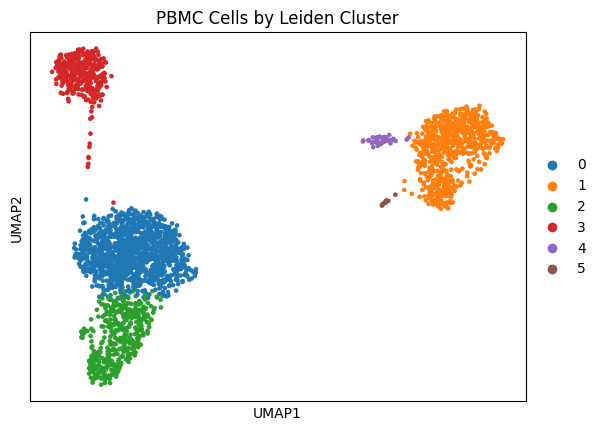

In [21]:
sc.tl.umap(
    adata_hvg,
    random_state=42
)

sc.pl.umap(
    adata_hvg,
    color="leiden",
    title="PBMC Cells by Leiden Cluster"
)

### UMAP Visualization

UMAP (Uniform Manifold Approximation and Projection) is a dimensionality reduction technique that represents cells in a two-dimensional space. It helps visualize similarities between cells based on their gene expression patterns.

### Parameters

- `adata_hvg`: The AnnData object containing the PCA results, neighbor graph and Leiden cluster labels.
- `random_state=42`: Sets a random seed to help make the UMAP layout reproducible.
- `color="leiden"`: Colors each cell according to its assigned Leiden cluster.
- `title`: Sets the plot title.

### Output

The UMAP plot displays each cell as a dot in two dimensions. Cells with similar gene expression patterns often appear near one another.

- **Dots:** Represent individual cells.
- **Colors:** Represent the five Leiden clusters, labeled 0–4.
- **Groups of dots:** Show patterns of similarity among cells.

The UMAP coordinates are stored in `adata_hvg.obsm["X_umap"]`.

### Key Takeaway

UMAP provides a visual representation of cell similarities, while Leiden assigns cells to computational clusters. The plot can help reveal patterns and relationships, but it cannot identify cell types on its own. Marker gene analysis is needed to help determine the biological identity of each cluster.

**Important:** UMAP axes have no direct biological meaning, and distances between separated groups should be interpreted cautiously.

In [22]:
# Transfer cluster labels to the normalized, log-transformed data
adata.obs["leiden"] = adata_hvg.obs["leiden"].reindex(
    adata.obs_names
).astype("category")

### Understanding the Two AnnData Objects

Both `adata` and `adata_hvg` contain the same 2,698 cells, but they differ in the genes they contain and how their expression values were processed.

| Property | `adata` | `adata_hvg` |
|---|---|---|
| Cells | 2,698 | 2,698 |
| Genes | All retained genes | 2,000 highly variable genes |
| Expression values | Normalized and log-transformed | Scaled for PCA |
| Leiden labels | Not yet assigned | Already assigned |

`adata_hvg` was created by selecting highly variable genes from `adata` and scaling them. PCA, neighbor graph construction and Leiden clustering were then performed using `adata_hvg`.

We now want to transfer the cluster labels to `adata` so that we can identify marker genes using the normalized, log-transformed expression values and all retained genes.

### Understanding the Code

**A. `adata.obs`**

The `obs` attribute is a pandas DataFrame containing cell-level metadata. Each row represents a cell, and columns store information such as quality-control metrics and cluster labels.

**B. `adata_hvg.obs["leiden"]`**

Retrieves the Leiden cluster label assigned to each cell. Your analysis identified five clusters: `0`, `1`, `2`, `3` and `4`.

**C. `.reindex(adata.obs_names)`**

Aligns the cluster labels with the cell names and order in `adata`.

This is important because pandas aligns data using index labels, not just row positions. Reindexing helps ensure that each cell receives its correct cluster label.

**D. `.astype("category")`**

Converts the cluster labels into a categorical variable. Cluster IDs are identifiers, not numerical measurements. For example, cluster 4 is not twice cluster 2.

**E. `adata.obs["leiden"] = ...`**

Stores the transferred labels in a new `leiden` column in `adata.obs`, making them available for downstream analysis.

### Example: Why Reindexing Matters

Suppose `adata_hvg` contains these cells and labels:

| Cell ID | Cluster |
|---|---|
| Cell_A | 0 |
| Cell_B | 1 |
| Cell_C | 0 |

If `adata` lists the cells in the order `Cell_C`, `Cell_A`, `Cell_B`, reindexing aligns the labels as `0`, `0`, `1`.

Without alignment, assigning labels based only on row positions could associate a cell with the wrong cluster.


In [23]:
# Identify genes that distinguish each cluster
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon"
)

ranking genes
    finished (0:00:15)


### Identifying Marker Genes

The `rank_genes_groups()` function identifies genes whose expression differs between each Leiden cluster and the remaining cells. These genes help us understand the biological characteristics of each cluster.

**Parameters:**

- `adata`: The AnnData object containing normalized, log-transformed expression values and Leiden cluster labels.
- `groupby="leiden"`: Groups cells according to their Leiden cluster labels (0–4).
- `method="wilcoxon"`: Uses the Wilcoxon rank-sum test to compare gene expression in each cluster against all other cells combined.

**How it works:**

For each cluster, Scanpy compares the expression of every gene in that cluster with its expression in the remaining cells. The Wilcoxon test uses ranked expression values to assess whether a gene tends to have different expression between the two groups.

In our analysis, it compares each Leiden cluster with all remaining cells to identify genes that may distinguish that cluster.

**Results:**

The results are stored in `adata.uns["rank_genes_groups"]` and include:

- `names`: Ranked gene names for each cluster.
- `scores`: Test statistics used to rank genes.
- `pvals`: Raw p-values.
- `pvals_adj`: P-values adjusted for multiple testing.
- `logfoldchanges`: Estimated log fold changes when available.

**Why is this important?**

Marker genes help us interpret clusters biologically. For example, `CD3D` and `CD3E` can indicate T-cell populations, while `MS4A1` can help identify B cells. These are examples, not confirmed identities for our clusters.

**Key takeaway:** Leiden clustering identifies groups of similar cells, while marker gene analysis helps us understand which genes distinguish those groups.

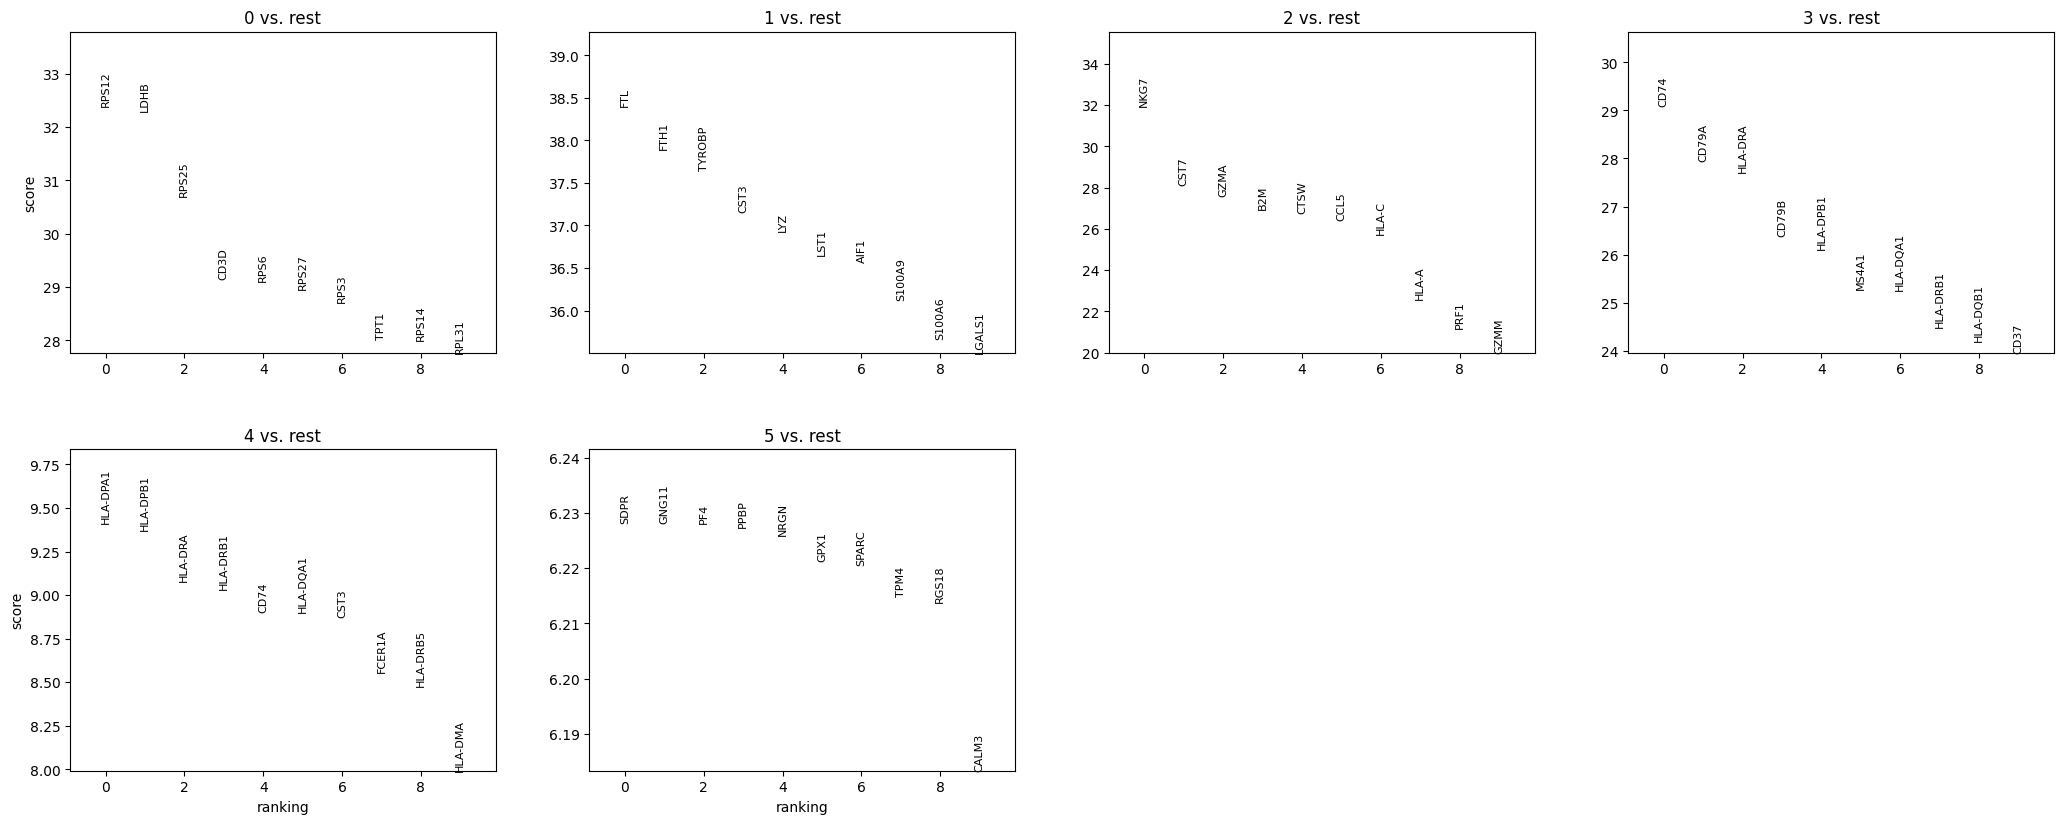

In [24]:
# Display the top 10 marker candidates per cluster
sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharey=False
)

In [29]:
# Verify Cell Alignment
print(adata.obs_names.equals(adata_hvg.obs_names))

True


If this returns `True`, their cell names match in both identity and order. If it returns `False`, reindexing **still aligns matching names**, but **you should check for missing labels before proceeding**.

### Visualizing Marker Genes

- `sc.pl.rank_genes_groups()` visualizes the differential-expression results calculated in the previous step.
- `n_genes=10` displays the top 10 ranked genes for each cluster.
- `sharey=False` allows each subplot to use its own y-axis scale instead of sharing the same scale across all clusters.

The plot helps identify genes that distinguish each cluster. Its exact appearance may vary depending on the plotting settings and Scanpy version.

### How to Interpret the Results

For each cluster, ask:

1. Which genes appear near the top of the ranking?
2. Are these genes associated with a known immune cell type?
3. Do multiple genes support the same cell type?
4. Do the expression patterns support the proposed cell-type annotation?

**Example:** If a cluster expresses several T-cell-associated genes, such as `CD3D`, `CD3E` and `IL7R`, this provides stronger evidence for a T-cell identity than relying on a single gene.

**Goal:** Move from numerical cluster IDs to meaningful biological interpretations by identifying the genes that characterize each cluster.

### Important Limitation

This Wilcoxon analysis is useful for exploratory marker discovery. However, cells from the same donor or sample are not independent biological replicates. For formal differential-expression studies, use methods that account for sample or donor structure.

In [25]:
#Create a marker-gene table
marker_genes = sc.get.rank_genes_groups_df(
    adata,
    group=None
)

marker_genes.head(10)

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RPS12,32.402813,1.053693,2.505231e-230,8.201624e-226
1,0,LDHB,32.303360,2.721958,6.275034e-229,1.027160e-224
2,0,RPS25,30.707815,1.182907,4.476287e-207,2.930894e-203
3,0,CD3D,29.141312,3.321475,1.076463e-186,4.405158e-183
4,0,RPS6,29.118750,0.855541,2.078577e-186,7.560941e-183
5,0,RPS27,28.952005,1.002605,2.647838e-184,8.668492e-181
6,0,RPS3,28.718616,0.859538,2.234204e-181,6.649396e-178
7,0,TPT1,28.029819,0.954157,7.039189e-173,1.646064e-169
8,0,RPS14,28.001450,0.760863,1.560054e-172,3.404870e-169
9,0,RPL31,27.766174,1.138867,1.111526e-169,2.274322e-166


### Extracting Marker-Gene Results

- `sc.get.rank_genes_groups_df()` extracts the differential-expression results from AnnData and converts them into a Pandas DataFrame.
- `adata` contains the expression data and the marker-gene analysis results.
- `group=None` retrieves the results for all clusters.
- `.head(10)` displays the first 10 rows of the resulting table.

**Important:** `.head(10)` displays only the first 10 rows of the combined results, not the top 10 genes from each cluster. To examine the top genes separately, we need to filter the table by cluster.

### Creating a Marker-Gene Table

After performing differential-expression analysis, Scanpy ranks genes for each cluster based on their expression differences compared with the remaining cells.

A marker-gene table organizes these results into a structured format, showing which genes are most strongly associated with each cluster.

The table can include:

- **Cluster:** The Leiden cluster to which the gene is associated.
- **Gene:** The name of the ranked gene.
- **Score:** The statistical score calculated by the Wilcoxon test.
- **Log fold change:** The estimated difference in gene expression between the cluster and the remaining cells.
- **Adjusted p-value:** The p-value corrected for multiple statistical tests.

**Purpose:** The table helps identify genes that characterize each cluster and provides evidence for assigning biological identities, such as T cells, B cells or NK cells.

By examining several marker genes together, we can make more reliable cell-type annotations.

In [32]:
genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]

for gene in genes:
    print(gene, gene in adata.var_names)

CD3D True
MS4A1 True
NKG7 True
LYZ True


### Checking Marker-Gene Availability in adata

This code checks whether the selected marker genes are present in the original AnnData object.

- `genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]` defines a list of four selected marker genes.
- `for gene in genes:` iterates through each gene in the list.
- `gene in adata.var_names` checks whether the gene exists in the gene names stored in `adata.var_names`.
- `print(gene, gene in adata.var_names)` displays the gene name and the result of the check.

**Purpose:** Confirm that the selected marker genes are available in the original dataset before visualizing their expression.

**Interpretation:** `True` means the gene is present, while `False` means it cannot be found in the dataset.

In [31]:
# Check whether the selected marker genes exist in adata_hvg
genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]

for gene in genes:
    print(gene, gene in adata_hvg.var_names)

CD3D False
MS4A1 False
NKG7 True
LYZ True


### Checking Marker-Gene Availability in adata_hvg

This code checks whether the selected marker genes are included in the subset of 2,000 highly variable genes.

- `genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]` defines the marker genes to check.
- `for gene in genes:` iterates through each selected gene.
- `gene in adata_hvg.var_names` checks whether the gene exists in the highly variable gene subset.
- `print(gene, gene in adata_hvg.var_names)` displays the gene name and whether it is present.

**Purpose:** Determine whether the selected marker genes were retained during highly variable gene selection.

**Interpretation:** `True` means the gene was selected as highly variable, while `False` means it was excluded from the 2,000-gene subset.

**Important:** A gene excluded during highly variable gene selection is not necessarily biologically unimportant. It simply was not selected based on the variability criteria used in this analysis.

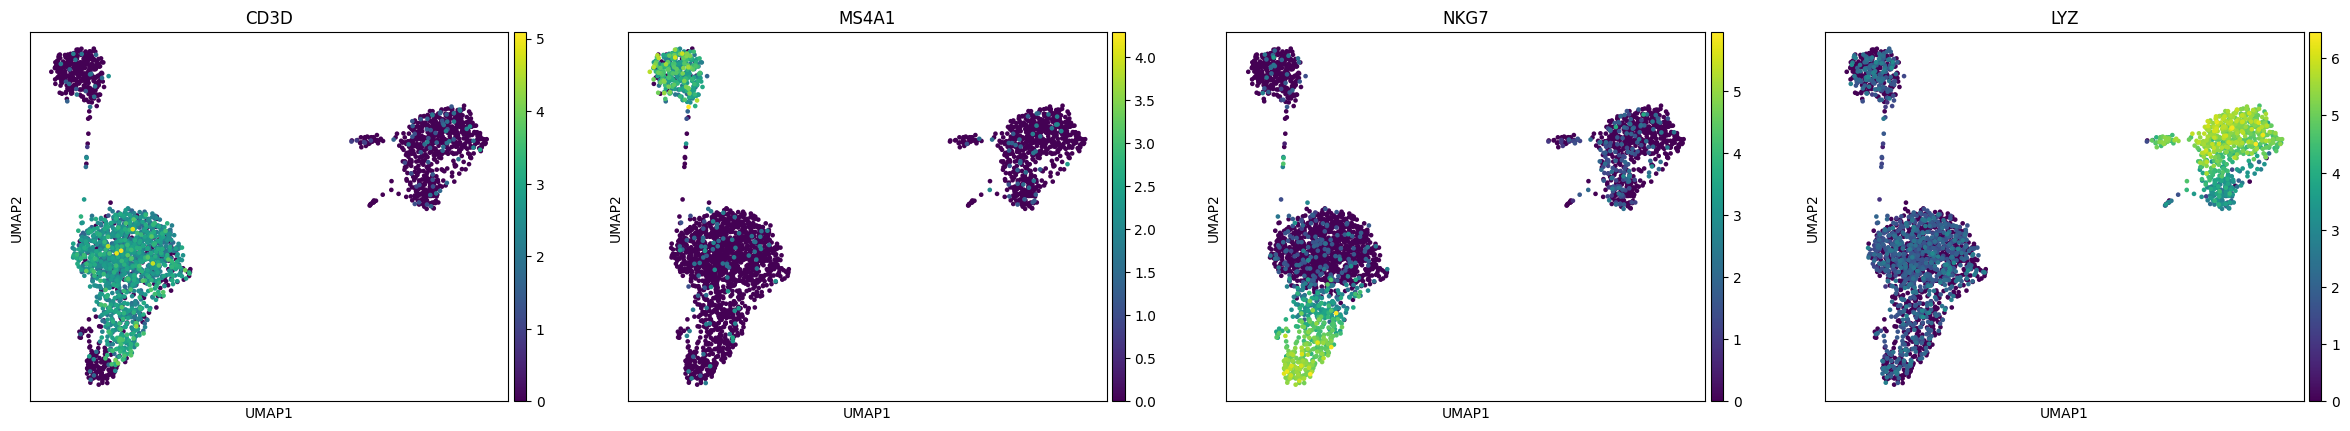

In [33]:
# Transfer UMAP coordinates if they are not already in adata
if "X_umap" not in adata.obsm:
    adata.obsm["X_umap"] = adata_hvg.obsm["X_umap"].copy()

# Visualize selected marker genes
sc.pl.umap(
    adata,
    color=["CD3D", "MS4A1", "NKG7", "LYZ"],
    cmap="viridis"
)

### Transferring UMAP Coordinates

- `adata.obsm` stores multidimensional data associated with cells, including dimensionality-reduction coordinates.
- `"X_umap"` represents the two-dimensional UMAP coordinates.
- `if "X_umap" not in adata.obsm` checks whether UMAP coordinates are already available in `adata`.
- `adata_hvg.obsm["X_umap"]` accesses the UMAP coordinates calculated previously using `adata_hvg`.
- `.copy()` creates a copy of these coordinates.
- `adata.obsm["X_umap"] = ...` stores the copied coordinates in `adata`.

**Purpose:** This allows us to visualize all retained genes using the same UMAP embedding previously calculated with the highly variable genes.

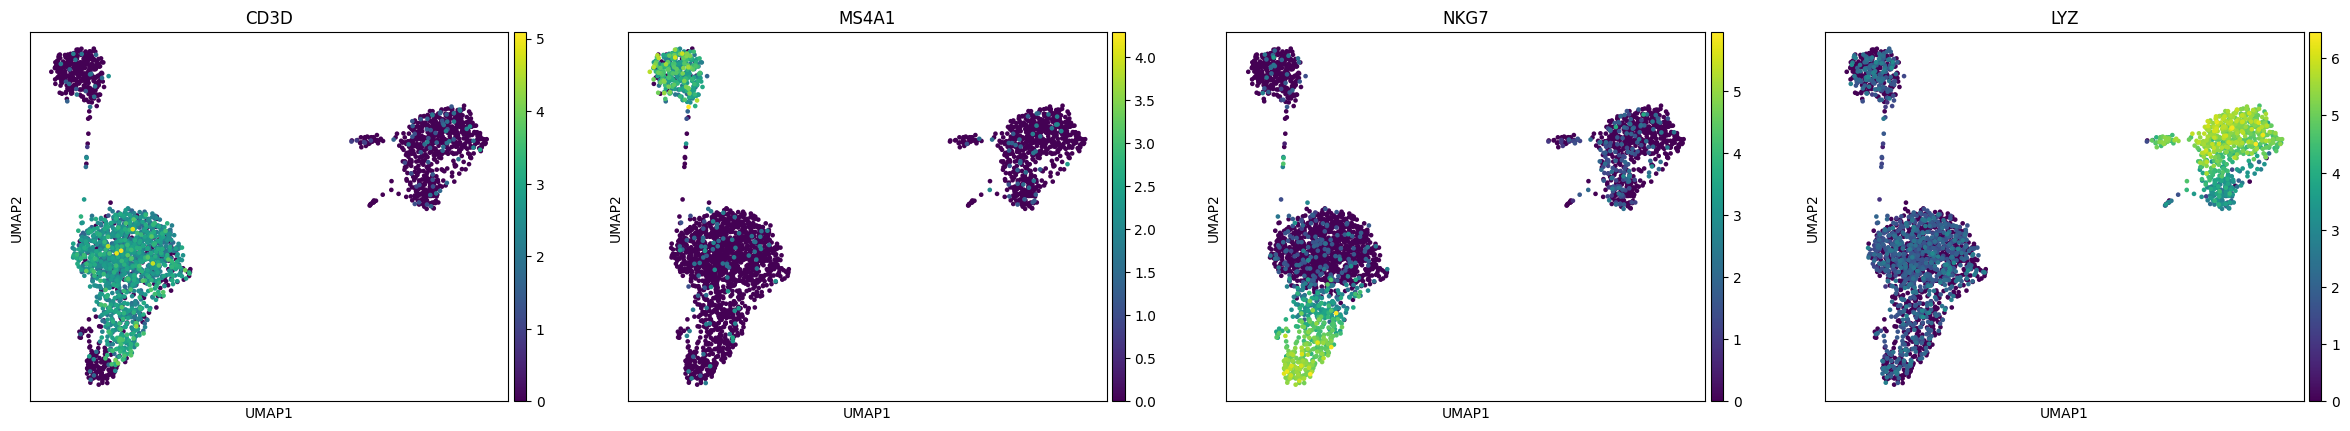

In [34]:
# Visualize selected marker genes
sc.pl.umap(
    adata,
    color=["CD3D", "MS4A1", "NKG7", "LYZ"],
    cmap="viridis"
)

### Visualizing Selected Marker Genes

We use `adata` instead of `adata_hvg` because `adata` contains all retained genes, including marker genes that were not selected as highly variable genes.

- `sc.pl.umap()` generates UMAP plots showing gene expression across cells.
- `adata` provides the normalized and log-transformed expression values for all retained genes.
- `color` specifies the four marker genes to visualize. Each gene is displayed in a separate plot.
- `cmap="viridis"` specifies the color map used to represent expression levels.

**Purpose:** Visualize the expression patterns of selected marker genes across cells and compare them with the Leiden clusters to help identify possible cell types.